# Assignment 3 (Track B): Platform APIs — World Bank WDI & WGI
**Name:** Mehmet Ali TARIM  
**Student ID:** 0095611  
**Date:** 23.11.2026  
**Course:** CSSM 502 - Advanced Data Analysis  


### Task 01: Choose a Source

#### Research Motivation
In comparative politics, Turkey and Argentina are classic "most-similar" cases regarding military interventions in the 1970s and 1980s, yet they diverged sharply in their transitions to democracy (Elçi, 2014). While qualitative comparative studies highlight how economic crises, inflation, and demographic pressures triggered the 1976 Argentine and 1980 Turkish coups—and how civilian control evolved afterward—these structural dynamics can also be observed empirically. Using the World Bank's World Development Indicators (WDI) API, this project collects longitudinal macroeconomic, demographic, and governance indicators for Turkey and Argentina (1960–2025) to systematically examine the structural conditions before, during, and after military rule.

#### Source Description & Social Science Relevance
The primary data source is the **World Bank Indicators REST API v2** (`https://api.worldbank.org/v2/`), specifically drawing from two official World Bank databases:
- **World Development Indicators (`source=2`):** The World Bank's primary collection of comparable cross-national macroeconomic, fiscal, and demographic time series.
- **Worldwide Governance Indicators (`source=3`):** Standardized perceptions-based composite governance estimates (`−2.5` to `+2.5`), beginning in 1996.

For comparative political scientists and computational social scientists, the World Bank API provides harmonized, machine-readable longitudinal indicators across countries and decades, making it possible to pair qualitative historical-institutional arguments (e.g., civil-military divergence) with systematic macro-structural time series.

#### Legality, Terms of Use, and Permissions
World Bank open datasets and API outputs are published under the **Creative Commons Attribution 4.0 International (CC BY 4.0)** license and governed by the [World Bank Terms of Use for Datasets](https://www.worldbank.org/en/about/legal/terms-of-use-for-datasets). The API requires **no authentication or API key** for read-only public indicator queries, imposes no non-commercial research restriction on aggregate country data, and explicitly supports programmatic retrieval with pagination and JSON output. To stay well within polite server usage, requests specify `per_page=50`, identify the academic project in the `User-Agent` header, and pause `1` second between consecutive calls.

#### Selected Indicators
| Dimension | Indicator Code | Source ID | Indicator Name |
| :--- | :--- | :---: | :--- |
| `political` | `MS.MIL.XPND.GD.ZS` | `2` | Military expenditure (% of GDP) — civil-military proxy |
| `political` | `GOV_WGI_VA.EST` | `3` | WGI Voice & Accountability (estimate, −2.5 to +2.5), 1996+ only |
| `population` | `SP.POP.TOTL` | `2` | Population, total |
| `population` | `SP.URB.TOTL.IN.ZS` | `2` | Urban population (% of total population) |
| `economy` | `NY.GDP.PCAP.KD` | `2` | GDP per capita (constant 2015 US$) |
| `economy` | `NY.GDP.DEFL.KD.ZG` | `2` | Inflation, GDP deflator (annual %) |

#### Indicator Selection Notes
- **Inflation proxy:** Consumer Price Index inflation (`FP.CPI.TOTL.ZG`) was rejected because Argentina only has values for **2018–2024** in WDI following the INDEC statistical credibility crisis; `NY.GDP.DEFL.KD.ZG` (GDP deflator) provides consistent 1961–2025 coverage for both countries.
- **Pre-1996 governance gap:** The World Bank API has no pre-1996 democracy index (`GOV_WGI_VA.EST` begins in 1996). To contextualize pre-1996 regime shifts without introducing an external dataset, military-rule periods are coded via a binary `military_rule` dummy variable and shaded directly in the longitudinal visualization.

#### Primary Theoretical Reference
Elçi, E. (2014). *A comparative analysis of civil-military relations in Turkey and Argentina during the 1970s and 1980s* [Master's thesis, Dokuz Eylül University, Graduate School of Social Sciences]. İzmir.


### Task 02: Data Collection via World Bank API v2

We collect all six indicators for Turkey (`TUR`) and Argentina (`ARG`) over `1960:2025` using `requests` with:
- Explicit pagination handling (`per_page=50`, looping `page = 1 ... meta["pages"]`)
- Polite rate limiting (`time.sleep(1)` after every request)
- Exponential backoff retries (up to 3 attempts on HTTP `429`/`5xx` or network errors)
- Explicit checks for World Bank JSON error payloads
- Environment-variable API key convention (`os.getenv("WB_API_KEY")`), documented as optional because the World Bank Indicators API is open and unauthenticated.


In [ ]:
import itertools
import os
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.ticker import FuncFormatter

# Standard env-var pattern for API keys; World Bank API v2 does not require authentication
API_KEY = os.getenv("WB_API_KEY")  # not required by World Bank; pattern kept for good practice

BASE = "https://api.worldbank.org/v2/country/TUR;ARG/indicator/{code}"
HEADERS = {"User-Agent": "CSSM502-Academic-Research/1.0 (Mehmet Ali Tarim)"}

# Değişkenleri seçtim
INDICATORS = [
    ("political", "MS.MIL.XPND.GD.ZS", 2),
    ("political", "GOV_WGI_VA.EST", 3),
    ("population", "SP.POP.TOTL", 2),
    ("population", "SP.URB.TOTL.IN.ZS", 2),
    ("economy", "NY.GDP.PCAP.KD", 2),
    ("economy", "NY.GDP.DEFL.KD.ZG", 2),
]

print("API_KEY set:", API_KEY is not None)
print(f"Configured {len(INDICATORS)} indicators across TUR and ARG (1960-2025).")


API_KEY set: False
Configured 6 indicators across TUR and ARG (1960-2025).


In [8]:
def fetch_indicator(code: str, src: int, dimension: str, max_retries: int = 3):
    """Fetch all pages for one World Bank indicator for TUR and ARG (1960-2025)."""
    url = BASE.format(code=code)
    page = 1
    records = []
    pages_fetched = 0
    last_updated = None

    while True:
        params = {
            "format": "json",
            "date": "1960:2025",
            "per_page": 50,
            "page": page,
            "source": src,
        }

        resp = None
        for attempt in range(max_retries):
            try:
                resp = requests.get(url, params=params, headers=HEADERS, timeout=30)
                if resp.status_code in (429, 500, 502, 503, 504):
                    wait = 2 ** attempt
                    print(f"[{code}] HTTP {resp.status_code} on page {page}; retrying in {wait}s...")
                    time.sleep(wait)
                    continue
                resp.raise_for_status()
                break
            except requests.RequestException as exc:
                if attempt == max_retries - 1:
                    raise RuntimeError(f"Failed fetching {code} page {page}: {exc}") from exc
                wait = 2 ** attempt
                print(f"[{code}] Request error on page {page} ({exc}); retrying in {wait}s...")
                time.sleep(wait)
        else:
            raise RuntimeError(f"Exhausted retries for {code} page {page} (HTTP {resp.status_code})")

        time.sleep(1)  # Polite 1-second pause after every request
        pages_fetched += 1

        js = resp.json()
        # World Bank API returns a 1-element list with a 'message' key on parameter/API errors
        if isinstance(js, list) and len(js) == 1 and isinstance(js[0], dict) and "message" in js[0]:
            raise RuntimeError(f"World Bank API error for {code}: {js[0]['message']}")
        if not (isinstance(js, list) and len(js) >= 2 and isinstance(js[1], list)):
            raise RuntimeError(f"Unexpected World Bank API response format for {code}: {js}")

        meta, rows = js[0], js[1]
        last_updated = meta.get("lastupdated")
        total_pages = int(meta["pages"])
        print(
            f"[{code} | src={src}] page {page}/{total_pages} "
            f"-> {len(rows)} rows (lastupdated={last_updated})"
        )

        for row in rows:
            records.append(
                {
                    "country_code": row["countryiso3code"],
                    "country": row["country"]["value"],
                    "year": int(row["date"]),
                    "indicator_code": code,
                    "indicator_name": row["indicator"]["value"],
                    "dimension": dimension,
                    "value": row["value"],
                }
            )

        if page >= total_pages:
            break
        page += 1

    return records, {"indicator_code": code, "source_id": src, "pages": pages_fetched, "lastupdated": last_updated}


In [9]:
all_records = []
collection_log = []

for dimension, code, src in INDICATORS:
    recs, summary = fetch_indicator(code=code, src=src, dimension=dimension)
    all_records.extend(recs)
    collection_log.append(summary)

df_log = pd.DataFrame(collection_log)
print(f"\nTotal API pages requested: {df_log['pages'].sum()}")
print(f"Total raw observations collected: {len(all_records)}")
display(df_log)


[MS.MIL.XPND.GD.ZS | src=2] page 1/3 -> 50 rows (lastupdated=2026-11-11)
[MS.MIL.XPND.GD.ZS | src=2] page 2/3 -> 50 rows (lastupdated=2026-11-11)
[MS.MIL.XPND.GD.ZS | src=2] page 3/3 -> 32 rows (lastupdated=2026-11-11)
[GOV_WGI_VA.EST | src=3] page 1/2 -> 50 rows (lastupdated=2026-09-25)
[GOV_WGI_VA.EST | src=3] page 2/2 -> 4 rows (lastupdated=2026-09-25)
[SP.POP.TOTL | src=2] page 1/3 -> 50 rows (lastupdated=2026-11-11)
[SP.POP.TOTL | src=2] page 2/3 -> 50 rows (lastupdated=2026-11-11)
[SP.POP.TOTL | src=2] page 3/3 -> 32 rows (lastupdated=2026-11-11)
[SP.URB.TOTL.IN.ZS | src=2] page 1/3 -> 50 rows (lastupdated=2026-11-11)
[SP.URB.TOTL.IN.ZS | src=2] page 2/3 -> 50 rows (lastupdated=2026-11-11)
[SP.URB.TOTL.IN.ZS | src=2] page 3/3 -> 32 rows (lastupdated=2026-11-11)
[NY.GDP.PCAP.KD | src=2] page 1/3 -> 50 rows (lastupdated=2026-11-11)
[NY.GDP.PCAP.KD | src=2] page 2/3 -> 50 rows (lastupdated=2026-11-11)
[NY.GDP.PCAP.KD | src=2] page 3/3 -> 32 rows (lastupdated=2026-11-11)
[NY.GDP.DEFL

,indicator_code,source_id,pages,lastupdated
0,MS.MIL.XPND.GD.ZS,2,3,2026-11-11
1,GOV_WGI_VA.EST,3,2,2026-09-25
2,SP.POP.TOTL,2,3,2026-11-11
3,SP.URB.TOTL.IN.ZS,2,3,2026-11-11
4,NY.GDP.PCAP.KD,2,3,2026-11-11
5,NY.GDP.DEFL.KD.ZG,2,3,2026-11-11


### Task 03: Clean, Flatten, and Store

To obtain a reproducible, analysis-ready longitudinal table:
1. Convert the raw API payload into a `pandas.DataFrame` and enforce numeric types (`year` as integer, `value` as float).
2. Reindex onto a complete **balanced panel** covering all `6 indicators × 2 countries (ARG, TUR) × 66 years (1960–2025) = 792 rows`. Missing values are preserved explicitly as `NaN` and are **never imputed**.
3. Encode `military_rule` (`1` during junta/military-rule years, `0` otherwise):
   - **Argentina (`ARG`):** `1966–1973` (*Revolución Argentina*) and `1976–1983` (*Proceso de Reorganización Nacional*).
   - **Turkey (`TUR`):** `1960–1961` (post-May 1960 junta prior to the 1961 civilian transition) and `1980–1983` (September 12 military regime).
4. Sort deterministically by `indicator_code`, `country_code`, and `year`, and save to `A3_data.csv`.


In [10]:
# Zaten temiz bir dataset olduğundan sadece missing value bulunan yıllar (".." şeklindeki cell'ler) için dataframe'i temizleyip 
# processingden gecireceğim

df_raw = pd.DataFrame(all_records)
df_raw["year"] = df_raw["year"].astype(int)
df_raw["value"] = pd.to_numeric(df_raw["value"], errors="coerce")

# Lookup maps so metadata columns remain complete across newly created balanced-panel rows
country_map = (
    df_raw[["country_code", "country"]]
    .drop_duplicates()
    .set_index("country_code")["country"]
    .to_dict()
)
indicator_name_map = (
    df_raw[["indicator_code", "indicator_name"]]
    .drop_duplicates()
    .set_index("indicator_code")["indicator_name"]
    .to_dict()
)
dimension_map = {code: dim for dim, code, _ in INDICATORS}

# 6 değişken x 2 ülke x 66 yıl = 792 rows -- alışverişler
ind_codes = [code for _, code, _ in INDICATORS]
countries = ["ARG", "TUR"]
years = list(range(1960, 2026))

full_index = pd.MultiIndex.from_tuples(
    list(itertools.product(ind_codes, countries, years)),
    names=["indicator_code", "country_code", "year"],
)

df = (df_raw.set_index(["indicator_code", "country_code", "year"])[["value"]].reindex(full_index).reset_index())

df["country"] = df["country_code"].map(country_map)
df["indicator_name"] = df["indicator_code"].map(indicator_name_map)
df["dimension"] = df["indicator_code"].map(dimension_map)

# Military-rule dummy coding
arg_mil = (df["country_code"] == "ARG") & (
    df["year"].between(1966, 1973) | df["year"].between(1976, 1983)
)
tur_mil = (df["country_code"] == "TUR") & (
    df["year"].between(1960, 1961) | df["year"].between(1980, 1983)
)
df["military_rule"] = (arg_mil | tur_mil).astype(int)

# sütun isimleri şekli
df = df[
    [
        "country_code",
        "country",
        "year",
        "indicator_code",
        "indicator_name",
        "dimension",
        "value",
        "military_rule",
    ]
].sort_values(["indicator_code", "country_code", "year"]).reset_index(drop=True)

df.to_csv("A3_data.csv", index=False, encoding="utf-8")

print("Saved A3_data.csv")
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nTotal military_rule == 1 rows:", int(df["military_rule"].sum()))

# Missingness breakdown per indicator x country
def summarize_missing(group):
    n_miss = int(group["value"].isna().sum())
    miss_years = group.loc[group["value"].isna(), "year"].tolist()
    if len(miss_years) > 8:
        preview = f"{miss_years[0]}-{miss_years[-1]} (plus biennial gaps)"
    else:
        preview = str(miss_years)
    return pd.Series({"non_null": int(group["value"].notna().sum()), "missing": n_miss, "missing_years": preview})

missing_summary = df.groupby(["indicator_code", "country_code"]).apply(summarize_missing, include_groups=False)
print("\nMissing value summary by indicator and country:")
display(missing_summary)
display(df.head(10))


Saved A3_data.csv
Shape: (792, 8)

Data types:
 country_code          str
country               str
year                int64
indicator_code        str
indicator_name        str
dimension             str
value             float64
military_rule       int64
dtype: object

Total military_rule == 1 rows: 132

Missing value summary by indicator and country:


non_null  missing  \
indicator_code    country_code                      
GOV_WGI_VA.EST    ARG                 27       39   
                  TUR                 27       39   
MS.MIL.XPND.GD.ZS ARG                 66        0   
                  TUR                 66        0   
NY.GDP.DEFL.KD.ZG ARG                 65        1   
                  TUR                 65        1   
NY.GDP.PCAP.KD    ARG                 66        0   
                  TUR                 66        0   
SP.POP.TOTL       ARG                 66        0   
                  TUR                 66        0   
SP.URB.TOTL.IN.ZS ARG                 66        0   
                  TUR                 66        0   

                                                 missing_years  
indicator_code    country_code                                  
GOV_WGI_VA.EST    ARG           1960-2001 (plus biennial gaps)  
                  TUR           1960-2001 (plus biennial gaps)  
MS.MIL.XPND.GD.ZS ARG                                       []  
                  TUR                                       []  
NY.GDP.DEFL.KD.ZG ARG                                   [1960]  
                  TUR                                   [1960]  
NY.GDP.PCAP.KD    ARG                                       []  
                  TUR                                       []  
SP.POP.TOTL       ARG                                       []  
                  TUR                                       []  
SP.URB.TOTL.IN.ZS ARG                                       []  
                  TUR                                       []

,country_code,country,year,indicator_code,indicator_name,dimension,value,military_rule
0,ARG,Argentina,1960,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,0
1,ARG,Argentina,1961,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,0
2,ARG,Argentina,1962,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,0
3,ARG,Argentina,1963,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,0
4,ARG,Argentina,1964,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,0
5,ARG,Argentina,1965,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,0
6,ARG,Argentina,1966,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,1
7,ARG,Argentina,1967,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,1
8,ARG,Argentina,1968,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,1
9,ARG,Argentina,1969,GOV_WGI_VA.EST,Voice and Accountability - Governance estimate...,political,NaN,1


In [ ]:
# Descriptive Stats
desc = df.groupby(["indicator_code", "country_code"])["value"].describe().round(2)
display(desc)


count         mean          std          min  \
indicator_code    country_code                                                 
GOV_WGI_VA.EST    ARG            27.0         0.47         0.11         0.18   
                  TUR            27.0        -0.46         0.45        -1.11   
MS.MIL.XPND.GD.ZS ARG            66.0         1.59         0.96         0.56   
                  TUR            66.0         3.10         0.84         1.62   
NY.GDP.DEFL.KD.ZG ARG            65.0       159.37       459.04        -3.56   
                  TUR            65.0        34.51        32.06         2.35   
NY.GDP.PCAP.KD    ARG            66.0     10490.97      1951.31      6967.75   
                  TUR            66.0      6531.92      3648.11      2410.64   
SP.POP.TOTL       ARG            66.0  33649418.14   8110839.44  20386045.00   
                  TUR            66.0  57667717.09  17667954.69  28329898.00   
SP.URB.TOTL.IN.ZS ARG            66.0        85.65         5.94        71.72   
                  TUR            66.0        54.28        21.25        23.43   

                                        25%          50%          75%  \
indicator_code    country_code                                          
GOV_WGI_VA.EST    ARG                  0.43         0.46         0.54   
                  TUR                 -0.95        -0.36        -0.07   
MS.MIL.XPND.GD.ZS ARG                  0.85         1.32         1.92   
                  TUR                  2.34         3.26         3.64   
NY.GDP.DEFL.KD.ZG ARG                 15.38        29.02       105.28   
                  TUR                  7.88        23.29        54.06   
NY.GDP.PCAP.KD    ARG               9256.39      9994.22     12483.31   
                  TUR               3868.86      5278.81      8466.42   
SP.POP.TOTL       ARG           26387163.50  33923122.00  40747160.25   
                  TUR           42118312.50  58494642.50  71792324.00   
SP.URB.TOTL.IN.ZS ARG                 81.45        87.61        90.78   
                  TUR                 36.57        53.19        67.51   

                                        max  
indicator_code    country_code               
GOV_WGI_VA.EST    ARG                  0.65  
                  TUR                  0.09  
MS.MIL.XPND.GD.ZS ARG                  4.72  
                  TUR                  5.12  
NY.GDP.DEFL.KD.ZG ARG               3046.09  
                  TUR                157.83  
NY.GDP.PCAP.KD    ARG              14040.62  
                  TUR              15883.12  
SP.POP.TOTL       ARG           45851378.00  
                  TUR           85878556.00  
SP.URB.TOTL.IN.ZS ARG                 92.35  
                  TUR                 89.49

#### Missing Data Assessment
Across the balanced 792-row panel (`6 indicators × 2 countries × 66 years`), `712` observations are populated and `80` (`10.1%`) are `NaN`, reflecting structural source availability rather than scraping gaps:
- **`GOV_WGI_VA.EST` (39 missing years per country; 78 total):** The Worldwide Governance Indicators begin in `1996` and were published biennially (`1996`, `1998`, `2000`, then annually from `2002` through `2025`), leaving `1960–1995`, `1997`, `1999`, and `2001` as explicit `NaN` rows.
- **`NY.GDP.DEFL.KD.ZG` (1 missing year per country; 2 total):** Annual inflation in `1960` is `NaN` because computing an annual percentage change requires a `1959` baseline outside our `1960–2025` query window.
- **All remaining 4 indicators (`MS.MIL.XPND.GD.ZS`, `SP.POP.TOTL`, `SP.URB.TOTL.IN.ZS`, `NY.GDP.PCAP.KD`):** Complete `66/66` coverage (`0` missing values) for both Turkey and Argentina from `1960` through `2025`.


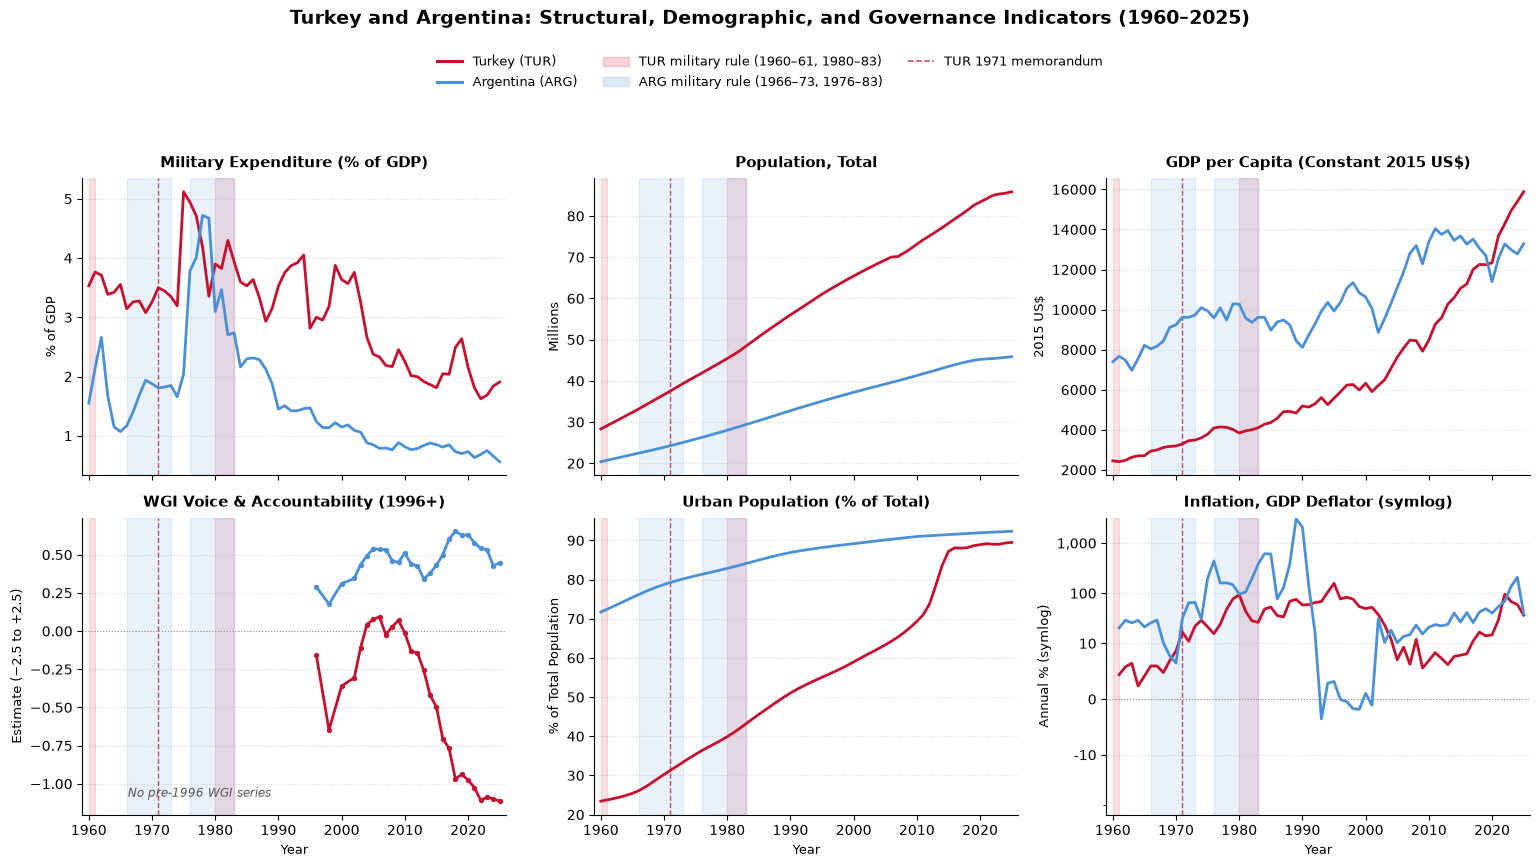

In [13]:
# Visualization kısmı
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

TUR_COLOR = "#C8102E"
ARG_COLOR = "#4A90D9"

# bazı verileri logaritmik yapısı gereği logaritmik visualize etmem gerekiyor

PANEL_LAYOUT = [
    ("MS.MIL.XPND.GD.ZS", "Military Expenditure (% of GDP)", "% of GDP", False, 1.0),
    ("SP.POP.TOTL", "Population, Total", "Millions", False, 1e6),
    ("NY.GDP.PCAP.KD", "GDP per Capita (Constant 2015 US$)", "2015 US$", False, 1.0),
    ("GOV_WGI_VA.EST", "WGI Voice & Accountability (1996+)", "Estimate (−2.5 to +2.5)", False, 1.0),
    ("SP.URB.TOTL.IN.ZS", "Urban Population (% of Total)", "% of Total Population", False, 1.0),
    ("NY.GDP.DEFL.KD.ZG", "Inflation, GDP Deflator (symlog)", "Annual % (symlog)", True, 1.0),]

fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.8), sharex=True)

# 6 tane plot çizmemek için tek plotta çizebileceğim kodlara revize ettim.

for ax, (code, title, ylabel, use_symlog, scale) in zip(axes.flat, PANEL_LAYOUT):
    sub = df[df["indicator_code"] == code]
    for ccode, color in [("TUR", TUR_COLOR), ("ARG", ARG_COLOR)]:
        cdf = sub[sub["country_code"] == ccode].sort_values("year")
        if code == "GOV_WGI_VA.EST":
            # WGI was biennial in 1996-2002; drop NaNs and show markers so 1996/1998/2000 appear
            cdf_plot = cdf.dropna(subset=["value"])
            ax.plot(
                cdf_plot["year"],
                cdf_plot["value"] / scale,
                color=color,
                linewidth=2.0,
                marker="o",
                markersize=2.8,
                label=ccode,
                zorder=3,
            )
        else:
            ax.plot(
                cdf["year"],
                cdf["value"] / scale,
                color=color,
                linewidth=2.0,
                label=ccode,
                zorder=3,
            )

    # Junta yönetimindeki yıllar için özel renk seçtim
    for start, end in [(1960, 1961), (1980, 1983)]:
        ax.axvspan(start, end, color=TUR_COLOR, alpha=0.12, zorder=1)
    for start, end in [(1966, 1973), (1976, 1983)]:
        ax.axvspan(start, end, color=ARG_COLOR, alpha=0.12, zorder=1)

    # 1971 muhtırası sebebiyle o kısmı da belirttim
    ax.axvline(1971, color=TUR_COLOR, linestyle="--", linewidth=1.0, alpha=0.75, zorder=2)

    if use_symlog:
        ax.set_yscale("symlog", linthresh=10)
        ax.axhline(0, color="gray", linestyle=":", linewidth=0.8, zorder=1)
        ax.set_yticks([-10, 0, 10, 100, 1000])
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{int(y):,}"))

    if code == "GOV_WGI_VA.EST":
        ax.axhline(0, color="gray", linestyle=":", linewidth=0.8, zorder=1)
        ax.text(
            1977.5,
            0.05,
            "No pre-1996 WGI series",
            ha="center",
            va="bottom",
            fontsize=8.5,
            color="#555555",
            style="italic",
            transform=ax.get_xaxis_transform(),
        )

    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    ax.set_ylabel(ylabel, fontsize=9.5)
    ax.set_xlim(1959, 2026)
    ax.grid(axis="y", linestyle=":", alpha=0.45)

for ax in axes[1, :]:
    ax.set_xlabel("Year", fontsize=9.5)

legend_handles = [
    mlines.Line2D([], [], color=TUR_COLOR, linewidth=2.2, label="Turkey (TUR)"),
    mlines.Line2D([], [], color=ARG_COLOR, linewidth=2.2, label="Argentina (ARG)"),
    mpatches.Patch(color=TUR_COLOR, alpha=0.18, label="TUR military rule (1960–61, 1980–83)"),
    mpatches.Patch(color=ARG_COLOR, alpha=0.18, label="ARG military rule (1966–73, 1976–83)"),
    mlines.Line2D([], [], color=TUR_COLOR, linestyle="--", linewidth=1.1, alpha=0.8, label="TUR 1971 memorandum"),
]

fig.suptitle(
    "Turkey and Argentina: Structural, Demographic, and Governance Indicators (1960–2025)",
    fontsize=13.5,
    fontweight="bold",
    y=0.98,
)
fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.942),
    ncol=3,
    frameon=False,
    fontsize=9.2,
)
plt.tight_layout(rect=[0, 0, 1, 0.87])
plt.savefig("A3_figure.png", dpi=220, bbox_inches="tight")
plt.show()


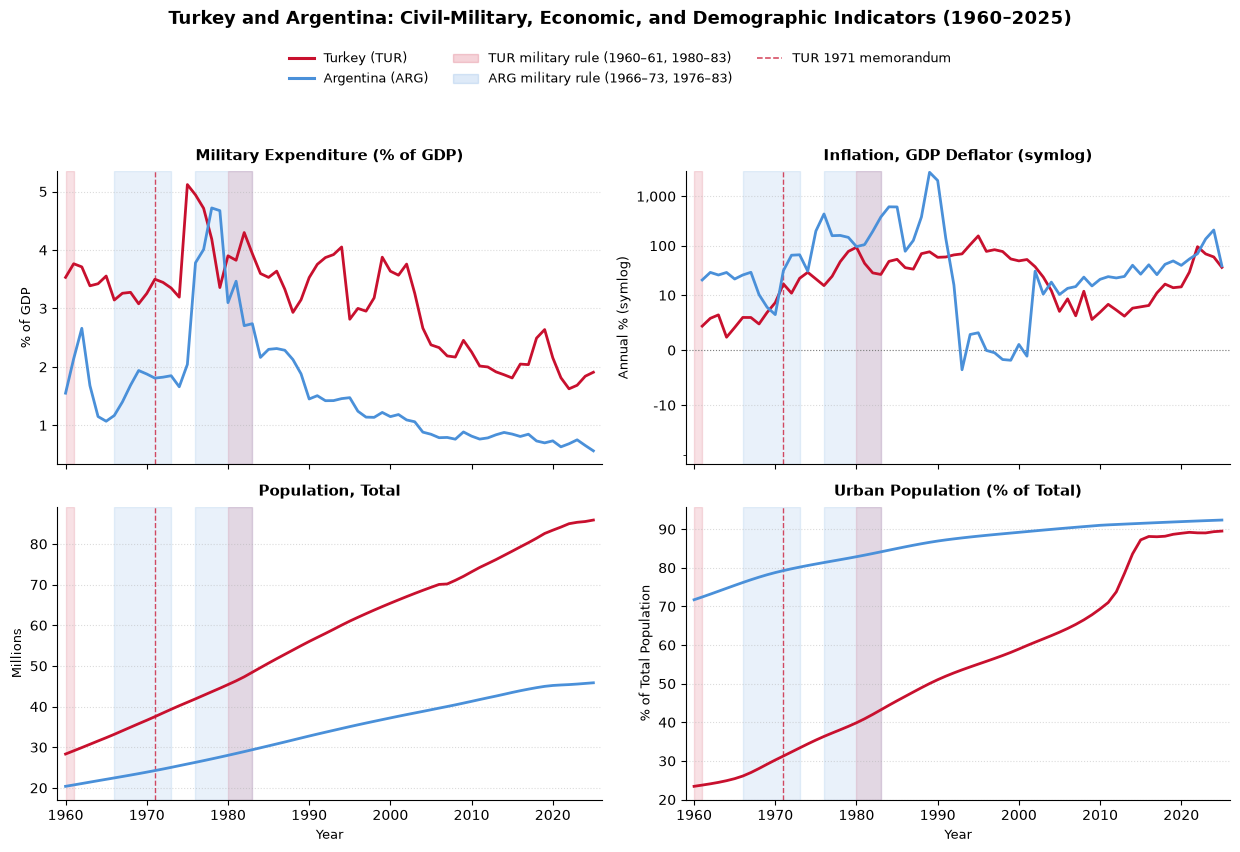

In [14]:
# bazı plotlar çok anlamsız oldu
# 6 göstergenin hepsini topladık (CSV'de duruyor), ama figürde ikisini eledik:
#  - GDP per capita (sabit 2015 US$): uzun dönemli yukarı trend, darbe/kriz şoklarını göstermiyor;
#    ülkeler arası seviye karşılaştırması da kura duyarlı.
#  - WGI Voice & Accountability: 1996'da başlıyor, son darbeden (1983) 13 yıl sonra;
#    darbe öncesi/sırası dönemi hiç görmüyor, panelin yarısı boş kalıyordu.
# Kalan 4 gösterge 1960-2025'i tam kapsıyor ve askeri yönetim dönemleriyle doğrudan konuşuyor.

KEEP_LAYOUT = [
    ("MS.MIL.XPND.GD.ZS", "Military Expenditure (% of GDP)", "% of GDP", 1.0),
    ("NY.GDP.DEFL.KD.ZG", "Inflation, GDP Deflator (symlog)", "Annual % (symlog)", 1.0),
    ("SP.POP.TOTL", "Population, Total", "Millions", 1e6),
    ("SP.URB.TOTL.IN.ZS", "Urban Population (% of Total)", "% of Total Population", 1.0),
]
MIL_SPANS = {"TUR": [(1960, 1961), (1980, 1983)], "ARG": [(1966, 1973), (1976, 1983)]}
COLORS = {"TUR": TUR_COLOR, "ARG": ARG_COLOR}

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.6), sharex=True)

for ax, (code, title, ylabel, scale) in zip(axes.flat, KEEP_LAYOUT):
    sub = df[df["indicator_code"] == code]
    for c in ["TUR", "ARG"]:
        cdf = sub[sub["country_code"] == c].sort_values("year")
        ax.plot(cdf["year"], cdf["value"] / scale, color=COLORS[c], lw=2, zorder=3)

    # askeri yönetim gölgeleri + 1971 muhtırası
    for c, spans in MIL_SPANS.items():
        for s, e in spans:
            ax.axvspan(s, e, color=COLORS[c], alpha=0.12, zorder=1)
    ax.axvline(1971, color=TUR_COLOR, ls="--", lw=1.0, alpha=0.75, zorder=2)

    if code == "NY.GDP.DEFL.KD.ZG":
        ax.set_yscale("symlog", linthresh=10)
        ax.axhline(0, color="gray", ls=":", lw=0.8)
        ax.set_yticks([-10, 0, 10, 100, 1000])
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{int(y):,}"))

    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    ax.set_ylabel(ylabel, fontsize=9.5)
    ax.set_xlim(1959, 2026)
    ax.grid(axis="y", ls=":", alpha=0.45)

for ax in axes[1, :]:
    ax.set_xlabel("Year", fontsize=9.5)

legend_handles = [
    mlines.Line2D([], [], color=TUR_COLOR, lw=2.2, label="Turkey (TUR)"),
    mlines.Line2D([], [], color=ARG_COLOR, lw=2.2, label="Argentina (ARG)"),
    mpatches.Patch(color=TUR_COLOR, alpha=0.18, label="TUR military rule (1960–61, 1980–83)"),
    mpatches.Patch(color=ARG_COLOR, alpha=0.18, label="ARG military rule (1966–73, 1976–83)"),
    mlines.Line2D([], [], color=TUR_COLOR, ls="--", lw=1.1, alpha=0.8, label="TUR 1971 memorandum"),
]
fig.suptitle("Turkey and Argentina: Civil-Military, Economic, and Demographic Indicators (1960–2025)",
             fontsize=13, fontweight="bold", y=0.985)
fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 0.95),
           ncol=3, frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.savefig("A3_figure.png", dpi=220, bbox_inches="tight")  # eski 6 panelli figürün üzerine yazar
plt.show()

### DAHA İYİ GÖZÜKÜYOR###


#### Empirical Observations from the Longitudinal Series
- **Pre-coup inflation & macroeconomic instability:** Both countries experienced acute inflationary surges ahead of military intervention. Argentina's GDP deflator jumped from `197.7%` in 1975 to `438.3%` in 1976 and stayed in triple digits through 1983 (`380.2%`), before culminating in hyperinflation (`3,046.1%` in 1989 and `2,078.3%` in 1990). Turkey's inflation surged prior to the 1980 coup (`76.7%` in 1979, `93.0%` in 1980), moderated under the 1980–83 regime (`26.3%` in 1983), and later peaked at `157.8%` in 1995.
- **Military expenditure as a civil-military proxy:** Argentina's defense burden climbed sharply under its 1976–83 junta (from `2.04%` in 1975 to `4.72%` in 1978) and then steadily declined after democratization to `0.56%` of GDP by 2025. Turkey exhibited a consistently higher military spending floor across both junta (`3.90%–4.30%` during 1980–83) and post-transition decades (`1.91%` in 2025).
- **Divergent demographic and income trajectories:** Argentina began far wealthier and more urbanized (`$7,397` GDP per capita and `71.7%` urban in 1960 vs. Turkey's `$2,449` and `23.4%`), whereas Turkey underwent rapid urbanization (`89.5%` by 2025) and stronger long-run per-capita growth, overtaking Argentina in the late 2010s (`$15,883` vs. `$13,287` in 2025).
- **Post-1996 democratic divergence:** Once WGI Voice & Accountability begins in 1996, Argentina remains consistently positive (`+0.18` to `+0.65`, `+0.45` in 2025), whereas Turkey fluctuates near zero until 2006 (`+0.09`) and declines markedly after 2013 (`−0.26` in 2013 to `−1.11` in 2025), echoing qualitative findings on divergent post-junta civil-military institutionalization (Elçi, 2014).


### Task 04: Ethics, Legality, and Data Dictionary

#### Data Dictionary (`A3_data.csv`)
| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| `country_code` | String (`str`) | ISO 3166-1 alpha-3 country identifier (`ARG` for Argentina, `TUR` for Turkey). |
| `country` | String (`str`) | Official country display name returned by the World Bank API (`Argentina`, `Turkiye`). |
| `year` | Integer (`int64`) | Calendar observation year spanning `1960` through `2025`. |
| `indicator_code` | String (`str`) | Official World Bank indicator identifier (e.g., `NY.GDP.PCAP.KD`, `GOV_WGI_VA.EST`). |
| `indicator_name` | String (`str`) | Full descriptive indicator title supplied by the World Bank metadata payload. |
| `dimension` | String (`str`) | Analytical domain assigned to the indicator (`political`, `population`, or `economy`). |
| `value` | Float (`float64`) | Reported numerical indicator value in native units; `NaN` indicates an unreported year. |
| `military_rule` | Integer (`int64`) | Binary indicator (`1` during military rule: ARG `1966–73`, `1976–83`; TUR `1960–61`, `1980–83`; `0` otherwise). |

#### Ethics, Legality, and Publication Standards
Unlike social media platforms that restrict automated collection or govern user-generated content (Freelon, 2018), the World Bank Indicators API v2 explicitly authorizes programmatic access under **CC BY 4.0** and documented [Terms of Use](https://www.worldbank.org/en/about/legal/terms-of-use-for-datasets), requiring neither authentication tokens nor circumvention of rate controls. Moreover, all six indicators represent **aggregate country-year statistics** containing zero personal data, identifiable individuals, or private trace records, minimizing privacy and consent risks emphasized in digital data-collection ethics (Jünger, 2018). For **published research**, four additional reproducibility safeguards would be required: (1) formal citation of the World Bank WDI/WGI databases including exact **retrieval dates**; (2) pinning and reporting the **data vintage** (`lastupdated` timestamps returned by the API metadata) because historical macroeconomic and WGI series are periodically revised retroactively; (3) archiving the raw JSON API responses alongside the cleaning script in a public replication archive (e.g., OSF or Harvard Dataverse); and (4) cross-validating the binary `military_rule` coding rules against established comparative regime datasets and historical sources (e.g., Elçi, 2014).

#### References
- Elçi, E. (2014). *A comparative analysis of civil-military relations in Turkey and Argentina during the 1970s and 1980s* [Master's thesis, Dokuz Eylül University, Graduate School of Social Sciences]. İzmir.
- Freelon, D. (2018). Computational research in the post-API age. *Political Communication*, 35(4), 665–668.
- Jünger, J. (2018). Mapping the field of automated data collection on the web: Data types, collection approaches and their research logic. In *Computational Social Science in the Age of Big Data* (pp. 104–130). Herbert von Halem.
- World Bank. (2026). *World Development Indicators (WDI) & Worldwide Governance Indicators (WGI) API v2*. https://api.worldbank.org/v2/
